In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import  zscore
data={
    "Student":["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_Hours":[2, 3, 4, 5, 4, 6, 5, 3, 4, 5, 6, 4, 5, 30, 3],
}
df=pd.DataFrame(data)

print("Original Dataset")
display(df)


Original Dataset


,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [2]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


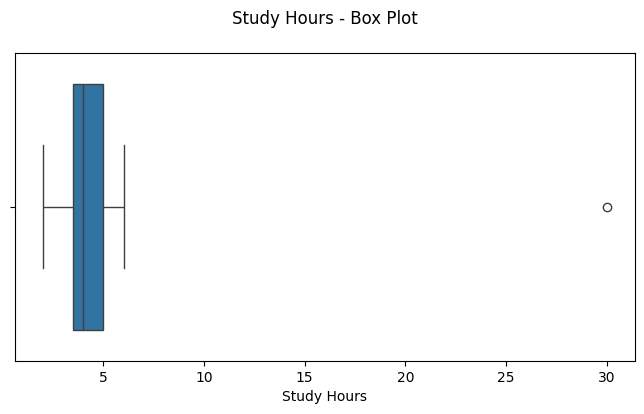

In [3]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_Hours"])
plt.title("Study Hours - Box Plot\n")
plt.xlabel("Study Hours")
plt.show()

#Step 1 - Find Q1 nad Q3

*   **Q1**=25th percentile
*   **Q3**=75th percentile





In [4]:
Q1=df["Study_Hours"].quantile(0.25)
Q3=df["Study_Hours"].quantile(0.75)

print("Q1:",Q1)
print("Q3:",Q3)

Q1: 3.5
Q3: 5.0


#1) IQR Method
Inter Quantile Range:

How many data is spread in range of 50. i.e, from Q1 to Q3

In [5]:
IQR=Q3-Q1
print("IQR:",IQR)

IQR: 1.5


In [6]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3-1.5*IQR

print("Lower Boundary:",lower_bound)
print("Upper Boundary:",upper_bound)

Lower Boundary: 1.25
Upper Boundary: 2.75


In [7]:
outliers_iqr=df[
    (df["Study_Hours"] < lower_bound) |
     (df["Study_Hours"] > upper_bound)
]
print("IQR Outliers")
display(outliers_iqr)

IQR Outliers


,Student,Study_Hours
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5
10,K,6


In [8]:
normal_data_iqr=df[
    (df["Study_Hours"] >= lower_bound) &
     (df["Study_Hours"] <= upper_bound)
]

display(normal_data_iqr)


,Student,Study_Hours
0,A,2


#2) Z - Score Method
The Z-Score tells us approxiamately

In [9]:
normal_data_iqr=df[
    (df["Study_Hours"] >= lower_bound) &
     (df["Study_Hours"] <= upper_bound)
]

display(normal_data_iqr)


,Student,Study_Hours
0,A,2


In [10]:
df["Z_Score"]=zscore(df["Study_Hours"])
print("Dataset with Z-Scores")
display(df)

Dataset with Z-Scores


,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


#Treatment 1 - Remove IQR Outliers

In [11]:
df_without_outliers=df[
    (df["Study_Hours"] >= lower_bound) &
     (df["Study_Hours"] <= upper_bound)
]

display(df_without_outliers)

,Student,Study_Hours,Z_Score
0,A,2,-0.602669


In [12]:
df_without_outliers =df[
    (df["Study_Hours"]>=lower_bound) &
    (df["Study_Hours"]<=upper_bound)
]
display(df_without_outliers)

,Student,Study_Hours,Z_Score
0,A,2,-0.602669


#Treatment 2 - Capping

In [13]:
df_capped=df.clip()

df_capped["Study_Hours"]=df["Study_Hours"].clip(
    lower_bound,
    upper_bound
)
display(df_capped)

,Student,Study_Hours,Z_Score
0,A,2.00,-0.602669
1,B,2.75,-0.449448
2,C,2.75,-0.296227
3,D,2.75,-0.143006
4,E,2.75,-0.296227
5,F,2.75,0.010215
6,G,2.75,-0.143006
7,H,2.75,-0.449448
8,I,2.75,-0.296227
9,J,2.75,-0.143006


In [14]:
print("Original data:")
df["Study_Hours"].describe()

print("After Removing Outliers:")
df_without_outliers["Study_Hours"].describe()

print("After Capping:")
df_capped["Study_Hours"].describe()

Original data:
After Removing Outliers:
After Capping:


,Study_Hours
count,15.000000
mean,2.700000
std,0.193649
min,2.000000
25%,2.750000
50%,2.750000
75%,2.750000
max,2.750000


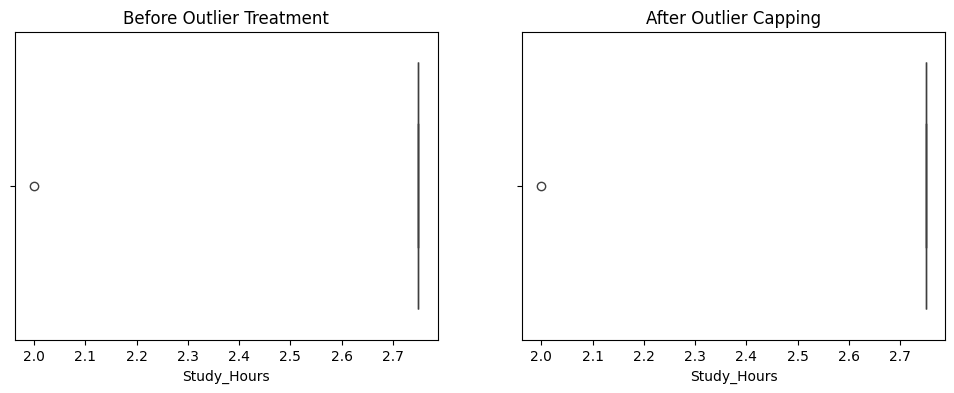

In [15]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Before Outlier Treatment")

plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("After Outlier Capping")

plt.show()